# Lab L2 – Partea B: modelul XGBoost, arborii, metricile, interpretarea

**Conținut:** model + early stopping, arbori, feature importance (gain/split/permutare), metrici, matrice de confuzie, ROC/PR, ponderarea claselor, praguri per clasă și experimente manuale cu hiperparametri.

**Configurația de bază:** `df_fe.csv`, One-Hot Encoding, outlieri păstrați, split 80/20 stratificat (`random_state=42`), CV `StratifiedKFold(5, shuffle=True, random_state=42)`, macro-F1 ca metrică principală. Baseline-ul este fără ponderi pentru continuitate cu strategia comună din A; `balanced` este comparat separat și rămâne o opțiune justificată pentru C.

**Prevenirea leakage-ului și refit:** early stopping împarte numai setul de train în fit/validare. Preprocesorul de selecție este fitat numai pe sub-setul fit. După alegerea numărului de runde, preprocesorul și XGBoost sunt refitate pe întregul `X_train`, fără a consulta testul. Curba de învățare păstrează istoricul etapei de selecție; modelul evaluat pe test este refit-uit pe tot train-ul.

**Reutilizare:** logica este în `src/metrics_eval.py`, iar metricile în `src/common.py`. `common.build_features()` acceptă `onehot`, `ordinal` și `native`; pentru native, `fit_xgb()` activează automat `enable_categorical=True`.

**Mediul care a generat outputurile salvate:** Python 3.13, pandas 2.2.3, NumPy 2.3.5, scikit-learn 1.8.0, XGBoost 3.1.3 și SciPy 1.17.0. Aceste versiuni diferă de cele fixate în `requirements.txt` (de exemplu, pandas 3.0.6, NumPy 2.5.3, scikit-learn 1.9.1 și XGBoost 3.4.1). Pentru predarea finală, rulați notebookul în mediul proiectului și verificați din nou valorile Markdown și graficele, deoarece versiunile pot modifica rezultatele. Graphviz (`dot`) trebuie instalat și în sistem pentru desenarea arborilor; în lipsă, funcția afișează dump-ul text.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---- gaseste radacina proiectului pornind fie din root, fie din folderul notebookului ----
HERE = Path.cwd().resolve()
ROOT = next(
    (p for p in [HERE, *HERE.parents] if (p / "src" / "metrics_eval.py").exists()),
    HERE,
)
SRC_DIR = ROOT / "src"
for p in (SRC_DIR, ROOT):
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
DATA_PATH = next(
    (p for p in [ROOT / "data" / "processed" / "df_fe.csv", ROOT / "df_fe.csv", HERE / "df_fe.csv"] if p.exists()),
    None,
)
assert DATA_PATH is not None, "Nu gasesc df_fe.csv (verifica data/processed sau folderul notebookului)."

import metrics_eval as B
from common import evaluate

# ---- CONFIG = strategia finala din Partea A (sectiunea A.9) ----
ENCODING         = "onehot"      # "onehot" | "ordinal" | "native"
USE_CLASS_WEIGHT = False         # baseline fara ponderi; varianta cu ponderi se compara in sectiunea 5b
TEST_SIZE        = 0.2
STRATIFY         = True
SAVE_DIR         = ROOT / "figures_B"  # director unic, independent de working directory
SAVE_DIR.mkdir(parents=True, exist_ok=True)

X, y, preprocessor = B.load_data(DATA_PATH, ENCODING)
X_train, X_test, y_train, y_test = B.make_split(X, y, test_size=TEST_SIZE, stratify=STRATIFY)
print("date:", DATA_PATH)
print("X:", X.shape, "| train:", X_train.shape, "| test:", X_test.shape)
print(pd.DataFrame({"train": y_train.value_counts().sort_index(), "test": y_test.value_counts().sort_index()}
                   ).set_axis(B.CLASS_NAMES))

date: D:\uni_ 3\ML\lab_1\data\processed\df_fe.csv
X: (2930, 92) | train: (2344, 92) | test: (586, 92)
          train  test
<100k       189    48
100-130k    407   102
130-180k    830   207
180-250k    549   137
250-400k    318    79
>=400k       51    13


In [2]:
# Verificare robusta One-Hot vs native: aceleasi 5 folduri stratificate si 150 boosting rounds.
encoding_cv = B.compare_onehot_native_cv(X_train, y_train, preprocessor, n_splits=5, n_estimators=150)
display(encoding_cv['fold_scores'].pivot(index='fold', columns='encoding', values='macro_f1').round(4))
display(encoding_cv['summary'].round(4))
delta_encoding = encoding_cv['summary'].loc['native', 'mean'] - encoding_cv['summary'].loc['onehot', 'mean']
print(f'Diferenta native - onehot (macro-F1 mediu CV): {delta_encoding:+.4f}')
print('Interpretare: comparam media si variatia pe folduri; diferenta observata nu trebuie confundata cu o garantie de superioritate pe date noi.')


encoding,native,onehot
fold,,
1,0.7357,0.7944
2,0.7618,0.7475
3,0.7413,0.7284
4,0.7360,0.7512
5,0.7533,0.7642


,mean,std,min,max
encoding,,,,
native,0.7456,0.0115,0.7357,0.7618
onehot,0.7571,0.0244,0.7284,0.7944


Diferenta native - onehot (macro-F1 mediu CV): -0.0115
Interpretare: comparam media si variatia pe folduri; diferenta observata nu trebuie confundata cu o garantie de superioritate pe date noi.


**Setul de date și alegerea encoding-ului.** One-Hot și native categorical sunt comparate pe aceleași 5 folduri stratificate și același număr de boosting rounds. În outputul acestei rulări, macro-F1 mediu este **0,7571 ± 0,0244** pentru One-Hot și **0,7456 ± 0,0115** pentru native; diferența native − One-Hot este **−0,0115**. One-Hot are media mai mare în această comparație, așa că îl păstrăm pentru configurația de bază. Comparația este realizată prin CV pe train, nu prin alegerea encoding-ului după scorul de test.

**Model.** XGBoost multiclasă (`multi:softprob`), cu early stopping pe o validare internă extrasă exclusiv din train. Preprocesorul este fitat numai pe sub-setul intern de antrenare. După selectarea numărului de runde, modelul final este refit-uit pe întregul train. Setul de test nu participă la preprocesare, early stopping sau selecția encoding-ului.

runde folosite (best_iteration + 1): 115 | arbori totali in booster: 690
features dupa encoding: 299


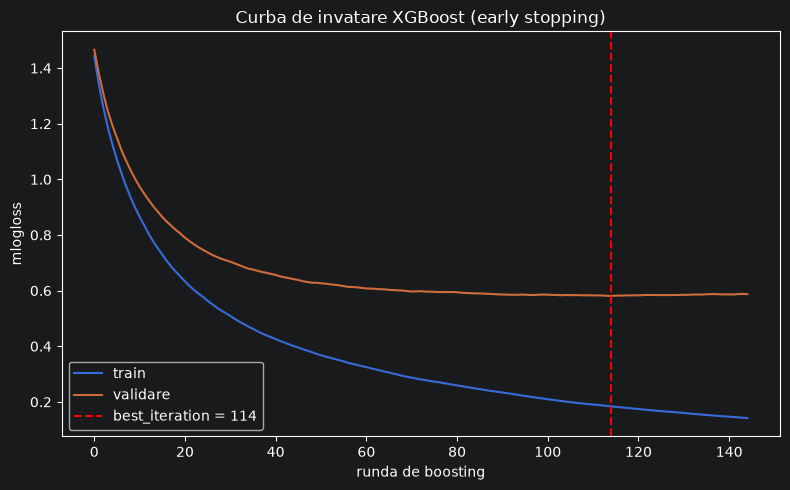

In [3]:
model = B.fit_xgb(X_train, y_train, preprocessor, use_class_weight=USE_CLASS_WEIGHT)
clf = model.named_steps["classifier"]
print("runde folosite (best_iteration + 1):", B.best_n_rounds(model), "| arbori totali in booster:", len(clf.get_booster().get_dump()))
print("features dupa encoding:", len(clf.get_booster().feature_names))
B.plot_training_curve(model, SAVE_DIR)

**Curba de învățare pe boosting rounds.** În outputul acestei rulări, `best_iteration = 114`, deci selecția a reținut **115 runde**. Modelul temporar de selecție a continuat antrenarea în perioada de patience, iar modelul final a fost refit-uit pe întregul train cu 115 runde, adică **690 de arbori** (6 arbori pentru fiecare rundă, câte unul pentru fiecare clasă). Diferența dintre curbele train și validare indică overfitting/varianță; early stopping limitează numărul de runde, iar refit-ul folosește toate observațiile din train.

      noduri  frunze  castig_total feature_radacina
tree                                               
0         21      11        447.42     QualxLivArea
684       25      13          7.13      Gr Liv Area


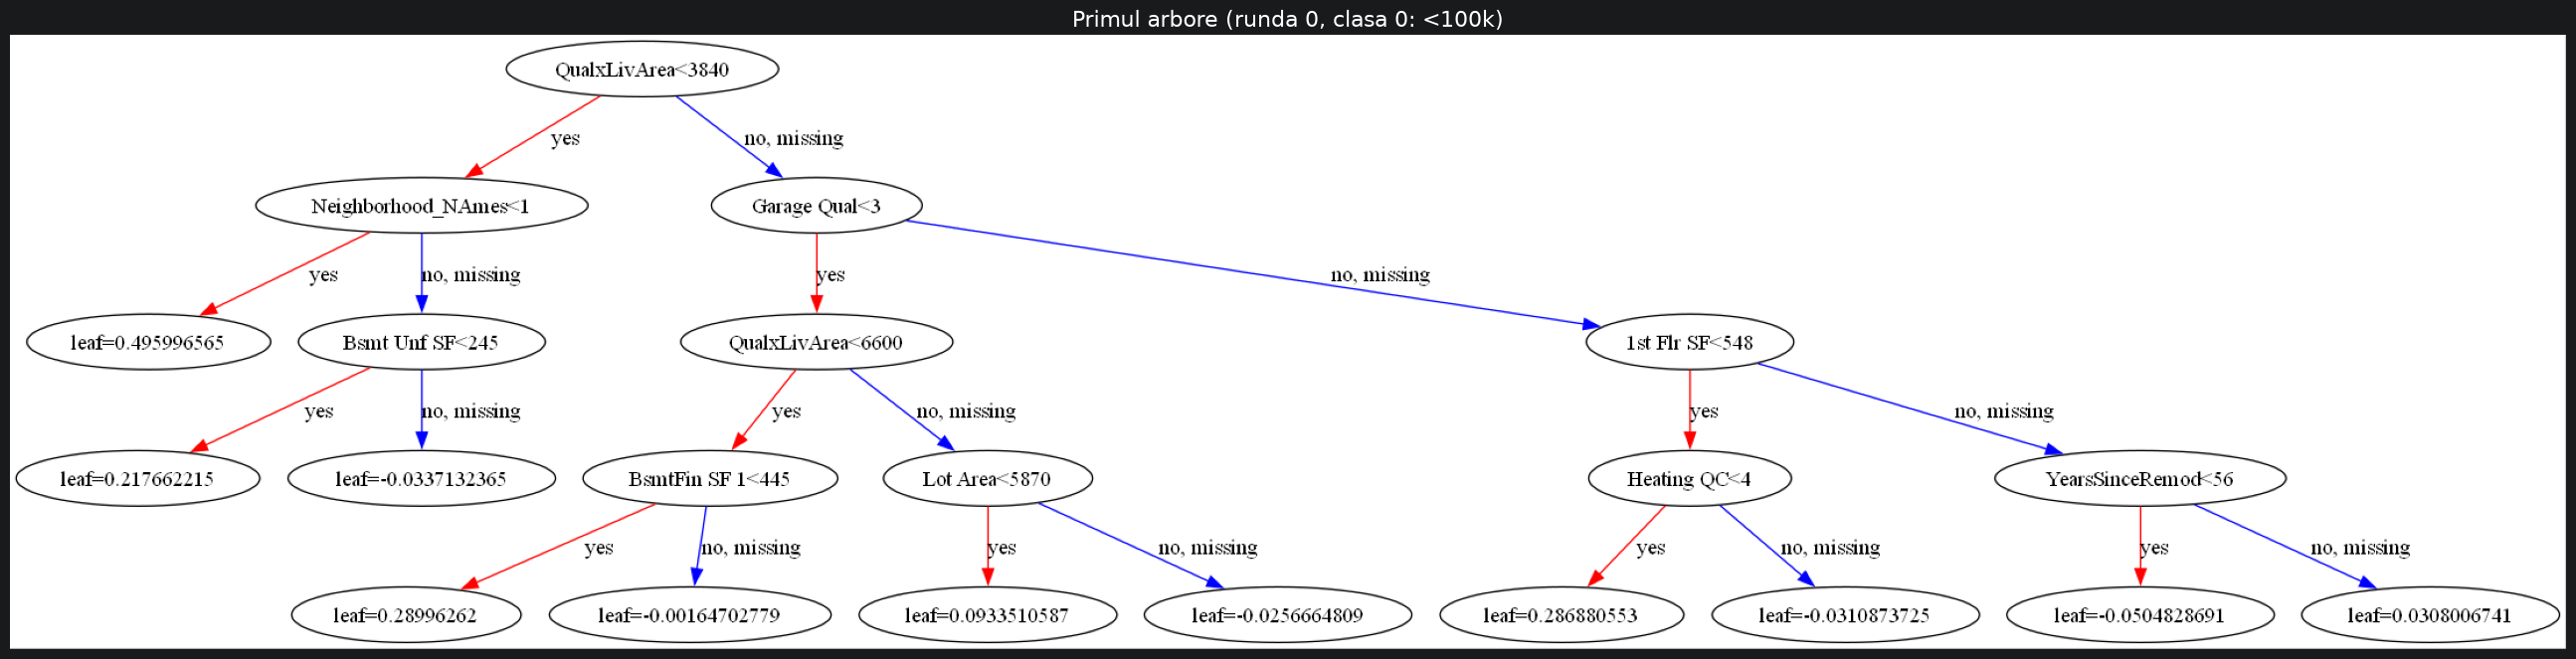

In [4]:
f_idx, b_idx = B.first_tree_idx(model, class_idx=0), B.best_tree_idx(model, class_idx=0)
print(B.tree_summary(model, [f_idx, b_idx]).round(2))
B.plot_tree_idx(model, f_idx, f"Primul arbore (runda 0, clasa 0: <100k)", save_dir=SAVE_DIR, name="B2_first_tree")

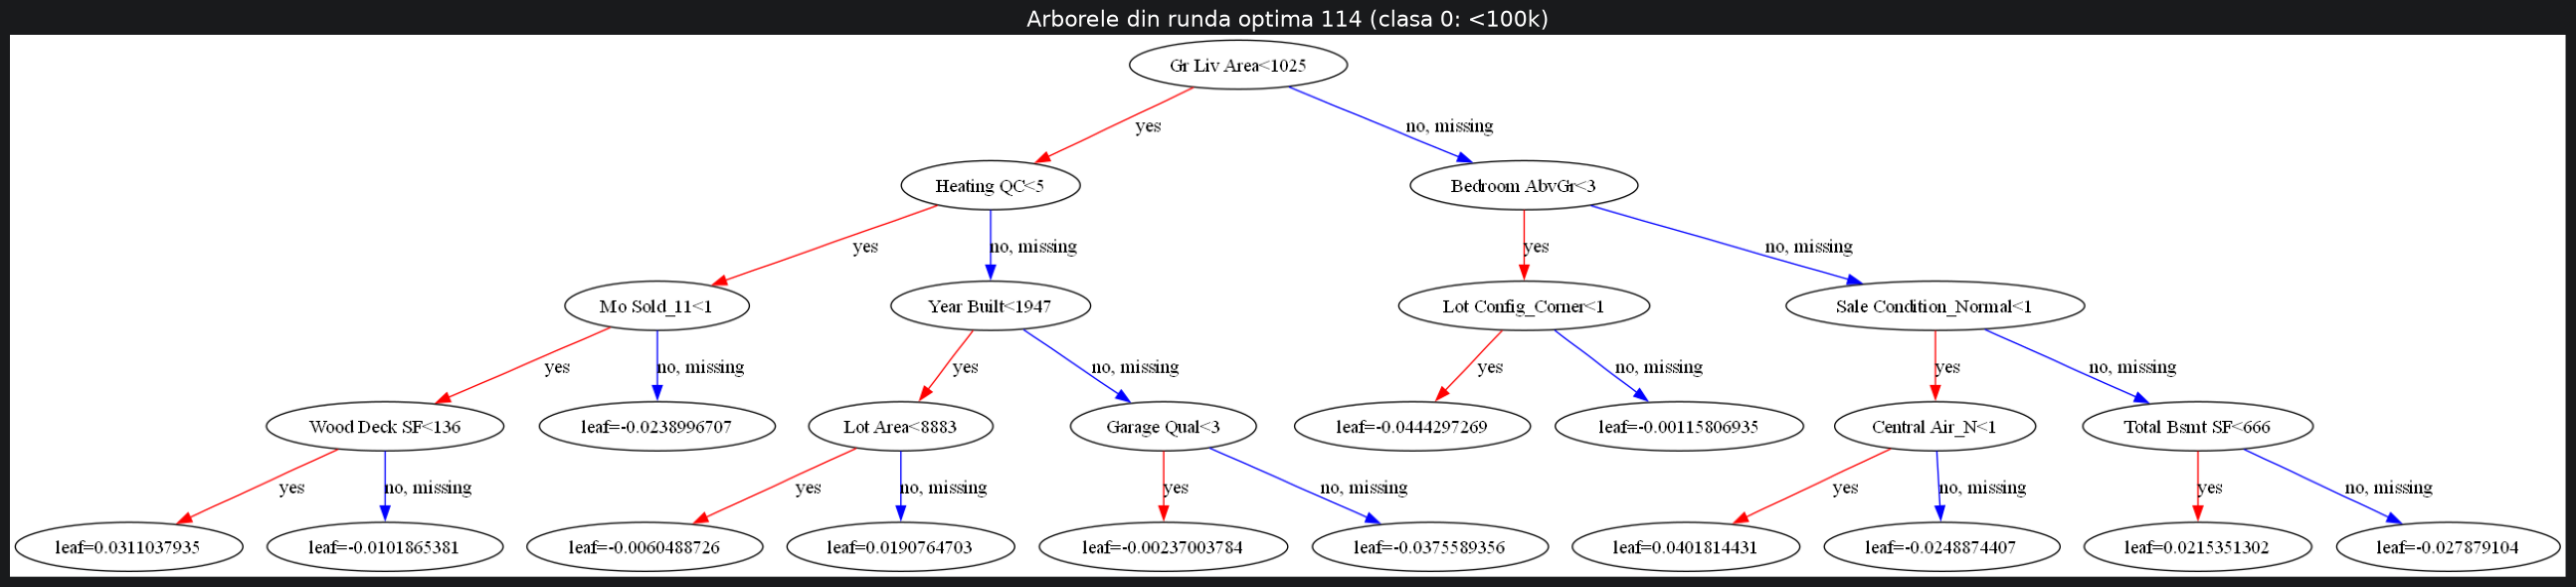

In [5]:
B.plot_tree_idx(model, b_idx, f"Arborele din runda optima {B.best_n_rounds(model)-1} (clasa 0: <100k)", save_dir=SAVE_DIR, name="B2_best_tree")

**Arborii.** În clasificarea multiclasă, fiecare rundă adaugă câte un arbore pentru fiecare clasă; indexul absolut este `runda × 6 + clasa`. Pentru clasa 0 (`<100k`), primul arbore este **index 0**, are **21 noduri**, **11 frunze**, gain total **447,42** și rădăcina **`QualxLivArea`**. Arborele clasei 0 din ultima rundă reținută este în runda **114**, index **684**; are **25 noduri**, **13 frunze**, gain total **7,13** și rădăcina **`Gr Liv Area`**.

Precizare: XGBoost nu selectează un arbore individual ca fiind cel mai bun; early stopping selectează numărul optim de runde pentru ansamblu. Arborele din acea rundă este prezentat aici ca reprezentare a ultimei runde păstrate, nu ca un arbore care ar fi optim independent.

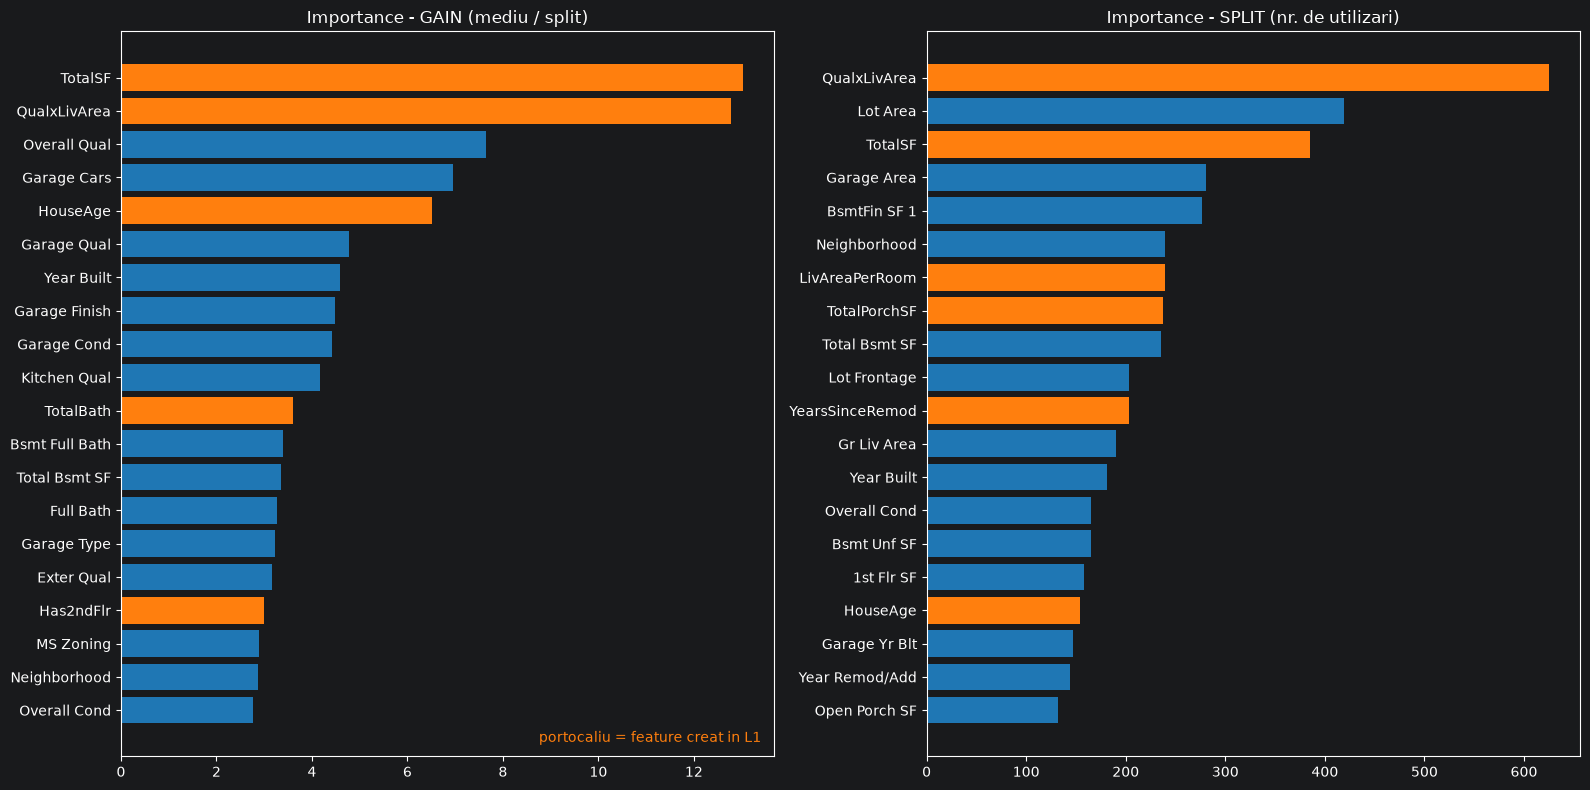

Corelatie Spearman intre rangul dupa gain si dupa split: 0.546


,gain,total_gain,split,rank_gain,rank_split
origin,,,,,
TotalSF,13.03,5017.82,385.0,1,3
QualxLivArea,12.77,7983.59,625.0,2,1
Overall Qual,7.65,995.10,130.0,3,21
Garage Cars,6.95,292.11,42.0,4,46
HouseAge,6.51,1002.13,154.0,5,17
Garage Qual,4.77,186.00,39.0,6,47
Year Built,4.58,828.92,181.0,7,13
Garage Finish,4.49,220.11,49.0,8,42
Garage Cond,4.42,88.49,20.0,9,65


In [6]:
imp = B.plot_importance(model, top=20, aggregate=True, save_dir=SAVE_DIR)
imp.head(15).round(2)

In [7]:
print("Feature-uri din L1 in top-10 dupa gain: ", [f for f in imp.sort_values("gain", ascending=False).index[:10] if f in B.FE_FEATURES])
print("Feature-uri din L1 in top-10 dupa split:", [f for f in imp.sort_values("split", ascending=False).index[:10] if f in B.FE_FEATURES])
imp.sort_values("split", ascending=False).head(10).round(2)

Feature-uri din L1 in top-10 dupa gain:  ['TotalSF', 'QualxLivArea', 'HouseAge']
Feature-uri din L1 in top-10 dupa split: ['QualxLivArea', 'TotalSF', 'LivAreaPerRoom', 'TotalPorchSF']


,gain,total_gain,split,rank_gain,rank_split
origin,,,,,
QualxLivArea,12.77,7983.59,625.0,2,1
Lot Area,2.21,926.43,419.0,32,2
TotalSF,13.03,5017.82,385.0,1,3
Garage Area,2.58,725.62,281.0,22,4
BsmtFin SF 1,2.42,669.06,277.0,26,5
Neighborhood,2.86,684.27,239.0,19,6
LivAreaPerRoom,1.48,352.74,239.0,55,6
TotalPorchSF,1.74,412.82,237.0,43,8
Total Bsmt SF,3.35,788.02,235.0,13,9


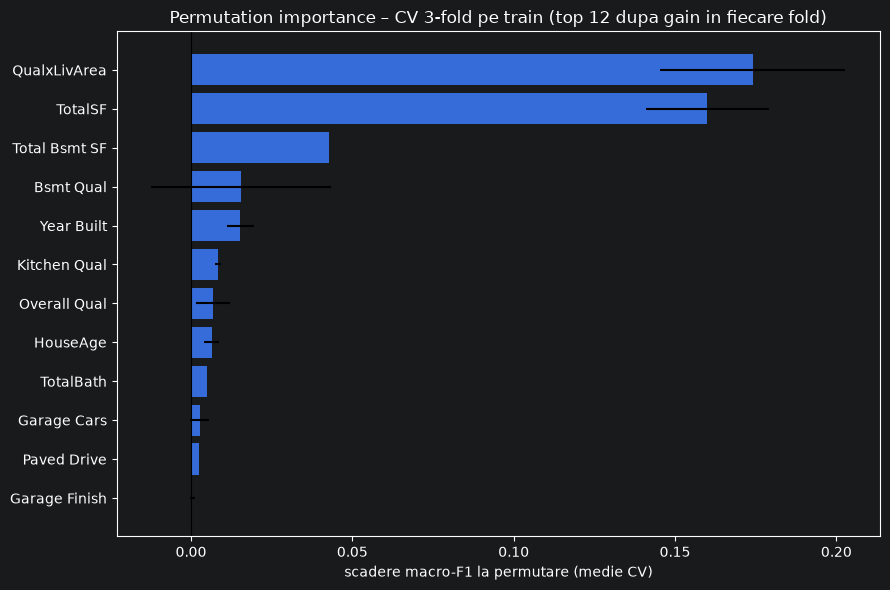

,importance_mean,importance_std_cv,folds_selected
QualxLivArea,0.1741,0.0287,3
TotalSF,0.1600,0.0191,3
Total Bsmt SF,0.0427,NaN,1
Bsmt Qual,0.0155,0.0278,2
Year Built,0.0153,0.0041,3
Kitchen Qual,0.0084,0.0010,3
Overall Qual,0.0068,0.0053,3
HouseAge,0.0064,0.0023,3
TotalBath,0.0048,NaN,1
Garage Cars,0.0026,0.0030,3


In [8]:
perm = B.plot_permutation_importance(model, X_train, y_train, save_dir=SAVE_DIR, n_splits=3, n_repeats=2)
display(perm.round(4))

**Feature importance.** `gain` este câștigul mediu asociat split-urilor unui feature, iar `split` (weight) este numărul de split-uri în care apare. Coloanele One-Hot sunt agregate înapoi la caracteristica originală. În outputul acestei rulări, primele caracteristici după gain sunt **`TotalSF` (13,03)**, **`QualxLivArea` (12,77)** și **`Overall Qual` (7,65)**. După numărul de split-uri, primele sunt **`QualxLivArea` (625)**, **`Lot Area` (419)** și **`TotalSF` (385)**. Corelația Spearman între valorile gain și split este **0,546**. În topul gain apar feature-uri create în L1, inclusiv `TotalSF`, `QualxLivArea` și `HouseAge`.

**Permutation importance** este calculată separat prin validare încrucișată pe setul de train: în fiecare fold, modelul este refit-uit pe foldul de antrenare, iar impactul permutării este măsurat numai pe foldul de validare. Pentru eficiență, în fiecare fold sunt selectate separat cele mai importante 12 caracteristici brute după gain-ul calculat numai pe foldul de antrenare; apoi fiecare este permutată de 2 ori pe foldul de validare. Tabelul raportează media, deviația standard și numărul de folduri în care caracteristica a fost selectată (`folds_selected`); `NaN` la deviația standard apare când caracteristica a fost selectată într-un singur fold. Setul de test nu este utilizat pentru această analiză. Numărul de runde este preluat din modelul baseline selectat pe train, deci analiza este descriptivă și interpretativă, nu o estimare complet independentă a performanței. Importanțele negative sau apropiate de zero indică faptul că permutarea nu a redus scorul macro-F1 în mod consistent. Caracteristicile corelate își pot împărți importanța, deci nici gain, nici split, nici permutation importance nu demonstrează cauzalitate.

Rezultatele modelului:
accuracy: 0.7628
precision_macro: 0.7562
recall_macro: 0.7293
f1_macro: 0.7412
f1_weighted: 0.7622
roc_auc_macro_ovr: 0.9637
average_precision_macro: 0.8423
ROC-AUC per clasa: {0: 0.9799, 1: 0.9397, 2: 0.9236, 3: 0.956, 4: 0.9872, 5: 0.9956}
Average Precision per clasa: {0: 0.8384, 1: 0.7395, 2: 0.8565, 3: 0.869, 4: 0.9271, 5: 0.8232}
Matricea de confuzie:
 [[ 33  13   2   0   0   0]
 [ 10  70  22   0   0   0]
 [  1  21 170  13   1   1]
 [  0   0  27 100   9   1]
 [  0   0   1  11  66   1]
 [  0   0   0   0   5   8]]

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.69      0.72        48
           1       0.67      0.69      0.68       102
           2       0.77      0.82      0.79       207
           3       0.81      0.73      0.77       137
           4       0.81      0.84      0.82        79
           5       0.73      0.62      0.67        13

    accuracy                           0.76       

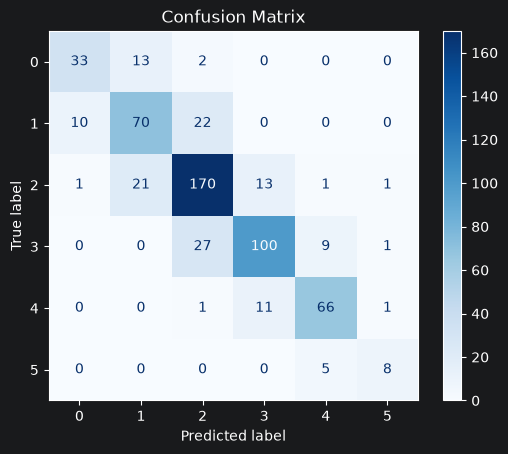

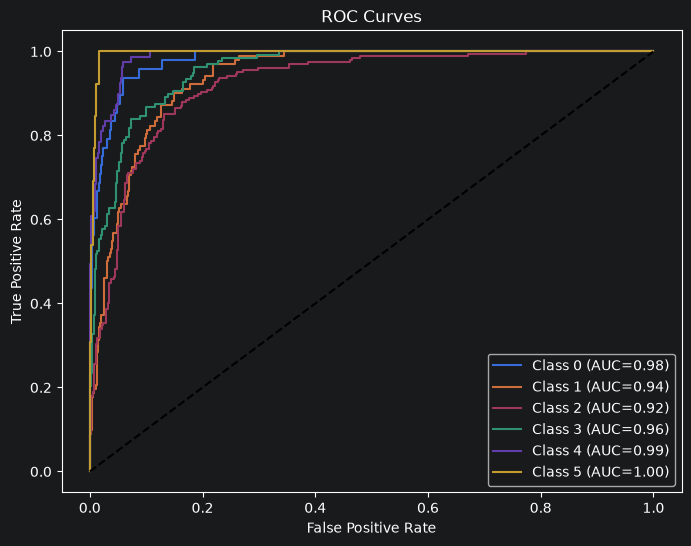

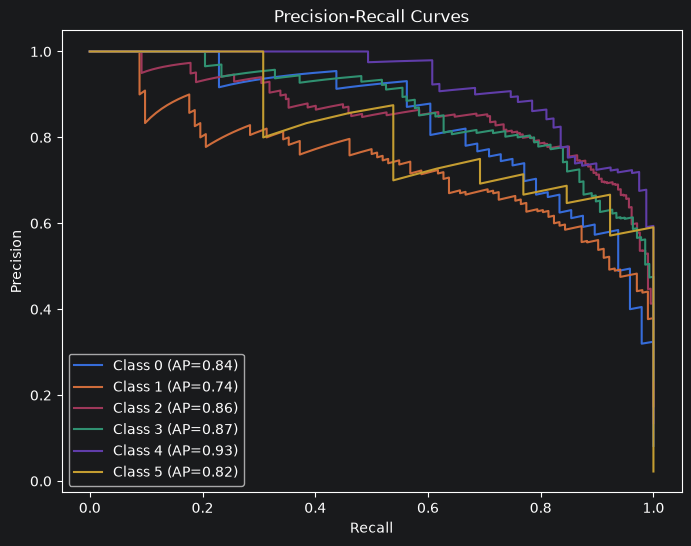

      clasa  precision  recall     f1  support
0     <100k      0.750   0.688  0.717       48
1  100-130k      0.673   0.686  0.680      102
2  130-180k      0.766   0.821  0.793      207
3  180-250k      0.806   0.730  0.766      137
4  250-400k      0.815   0.835  0.825       79
5    >=400k      0.727   0.615  0.667       13


In [9]:
res = B.evaluate_model(model, X_test, y_test, show_plots=True)

**Metrici pe test (586 observații).** În outputul acestei rulări, baseline-ul a obținut: **accuracy = 0,7628**, **macro-precision = 0,7562**, **macro-recall = 0,7293**, **macro-F1 = 0,7412** și **weighted-F1 = 0,7622**. ROC-AUC macro OvR este **0,9637**, iar Average Precision macro este **0,8423**.

ROC-AUC per clasă (0–5): **0,9799; 0,9397; 0,9236; 0,9560; 0,9872; 0,9956**. AP per clasă: **0,8384; 0,7395; 0,8565; 0,8690; 0,9271; 0,8232**. Aceste valori descriu separarea probabilistică one-vs-rest; nu înlocuiesc evaluarea etichetelor prezise prin macro-F1 și matricea de confuzie.

F1 per clasă este aproximativ **0,72; 0,68; 0,79; 0,77; 0,82; 0,67**. Clasa ≥400k are doar 13 observații în test, deci o singură predicție corectă/greșită modifică recall-ul cu aproximativ 7,7 puncte procentuale. Erorile se concentrează în principal între clase de preț vecine, ceea ce este plauzibil pentru intervale adiacente.

## 5b. Cu vs. fără `sample_weight` balanced (același model)

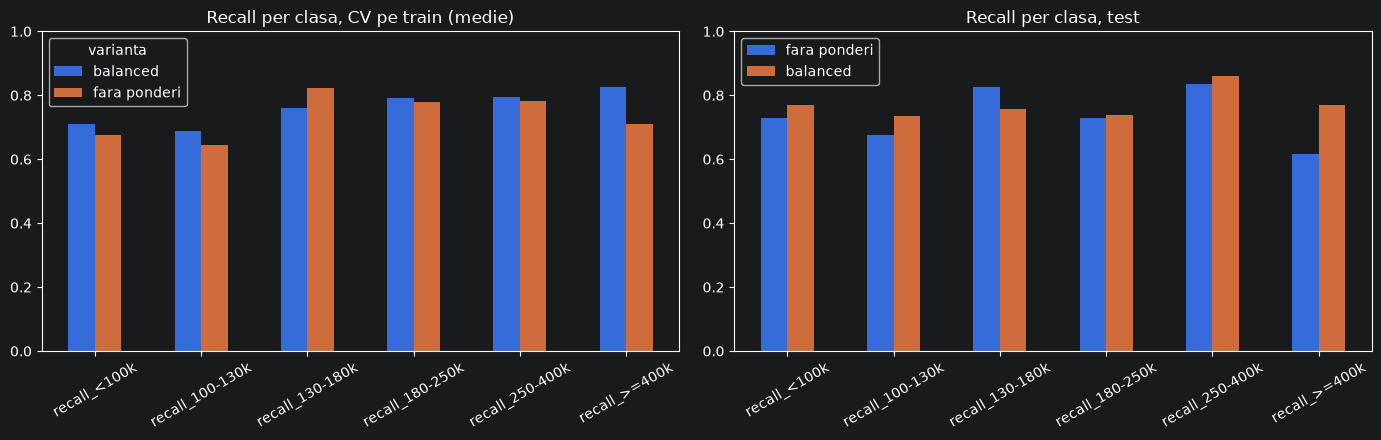

CV 5-fold pe train (medie si std):


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,accuracy_std,precision_macro_std,recall_macro_std,f1_macro_std,f1_weighted_std
varianta,,,,,,,,,,
balanced,0.7572,0.7707,0.7620,0.7631,0.7582,0.0128,0.0305,0.0136,0.0157,0.0130
fara ponderi,0.7628,0.7912,0.7367,0.7571,0.7617,0.0272,0.0437,0.0194,0.0244,0.0268


Recall per clasa, CV:


,recall_<100k,recall_100-130k,recall_130-180k,recall_180-250k,recall_250-400k,recall_>=400k
varianta,,,,,,
balanced,0.709,0.688,0.761,0.791,0.796,0.827
fara ponderi,0.677,0.646,0.824,0.780,0.783,0.711


TEST (un singur split):


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,runde
fara ponderi,0.7662,0.7610,0.7354,0.7469,0.7655,150.0
balanced,0.7645,0.7584,0.7720,0.7641,0.7653,150.0


,recall_<100k,recall_100-130k,recall_130-180k,recall_180-250k,recall_250-400k,recall_>=400k
fara ponderi,0.729,0.676,0.826,0.730,0.835,0.615
balanced,0.771,0.735,0.758,0.737,0.861,0.769


In [10]:
folds = B.make_folds(X_train, y_train, preprocessor, n_splits=5)   # StratifiedKFold(5, shuffle=True, random_state=42)
cw = B.compare_class_weights(X_train, y_train, X_test, y_test, preprocessor, folds=folds, save_dir=SAVE_DIR)
print("CV 5-fold pe train (medie si std):"); display(cw["cv_summary"].round(4))
print("Recall per clasa, CV:"); display(cw["cv_recall"].round(3))
print("TEST (un singur split):"); display(cw["test"].round(4)); display(cw["test_recall"].round(3))

**Ponderarea claselor.** Comparația folosește același protocol cu 150 de boosting rounds atât în CV, cât și pe test, astfel încât efectul ponderilor să nu fie confundat cu early stopping. Pe CV 5-fold, varianta balanced obține macro-F1 **0,7631 ± 0,0157**, față de **0,7571 ± 0,0244** fără ponderi. Balanced crește recall-ul macro (**0,7620** față de **0,7367**), dar reduce ușor accuracy (**0,7572** față de **0,7628**).

Pe test, în același protocol fix de 150 de runde, macro-F1 este **0,7641** balanced și **0,7469** fără ponderi. Testul este raportat descriptiv; selecția strategiei trebuie făcută pe CV, nu pe acest scor de test. Baseline-ul B rămâne fără ponderi pentru continuitate cu strategia comună din A, dar rezultatele CV justifică includerea lui `sample_weight_balanced` în spațiul de căutare Optuna din C.

Macro-F1 pe OOF (train): argmax=0.7457 | praguri optimizate=0.7679


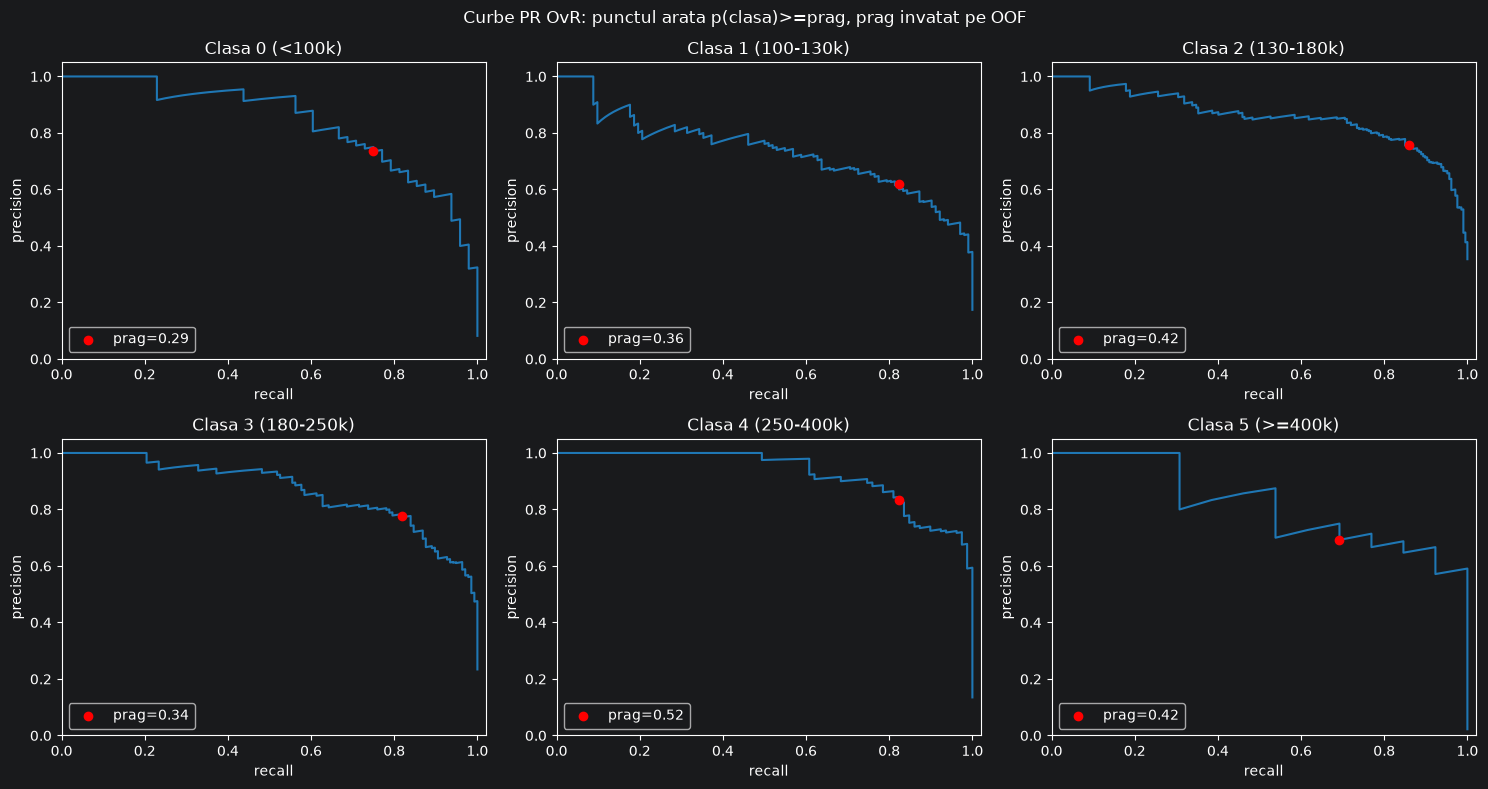

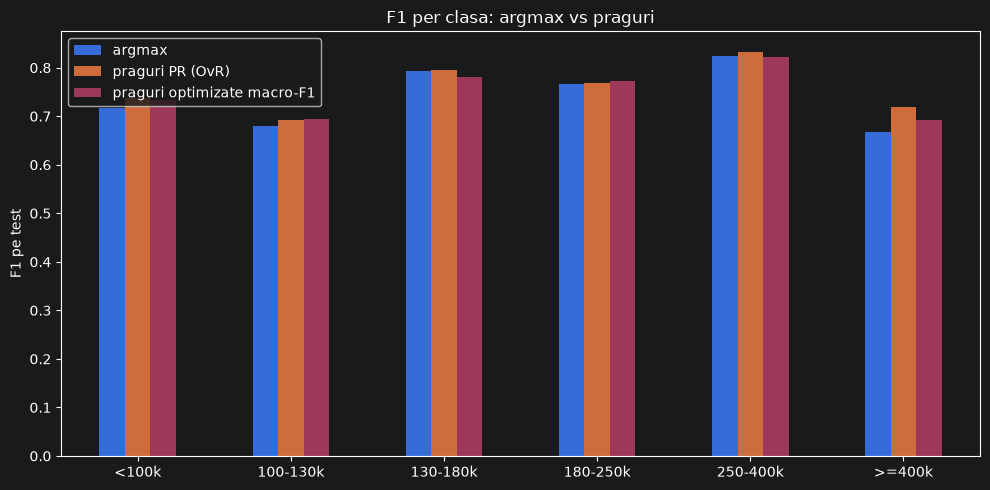

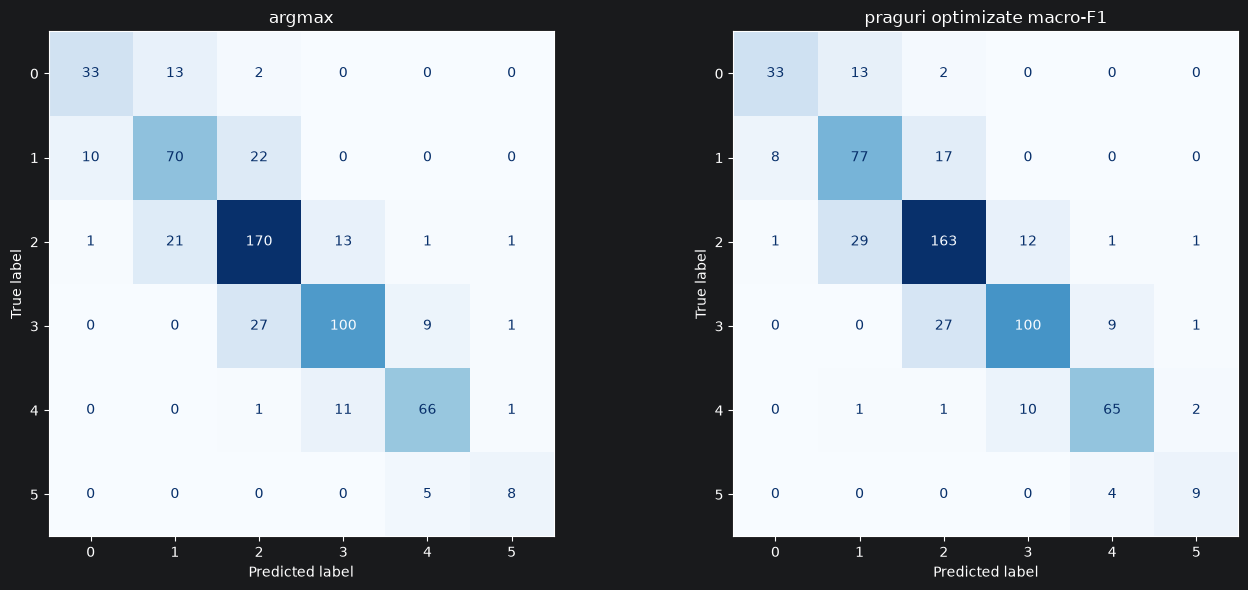

,prag PR (OvR),F1 OvR pe OOF,prag optimizat macro-F1
<100k,0.286,0.753,1.000
100-130k,0.361,0.677,0.786
130-180k,0.422,0.798,1.175
180-250k,0.340,0.789,1.380
250-400k,0.522,0.806,1.495
>=400k,0.415,0.837,1.000


,accuracy,precision_macro,recall_macro,f1_macro
argmax,0.7628,0.7562,0.7293,0.7412
praguri PR (OvR),0.7696,0.7647,0.7515,0.7577
praguri optimizate macro-F1,0.7628,0.7564,0.7458,0.7493


,argmax,praguri PR (OvR),praguri optimizate macro-F1
<100k,0.717,0.737,0.733
100-130k,0.680,0.692,0.694
130-180k,0.793,0.795,0.782
180-250k,0.766,0.769,0.772
250-400k,0.825,0.833,0.823
>=400k,0.667,0.720,0.692


In [11]:
thr = B.threshold_analysis(model, X_train, y_train, X_test, y_test, save_dir=SAVE_DIR, use_class_weight=USE_CLASS_WEIGHT)
display(thr["thresholds"].round(3)); display(thr["summary"].round(4)); display(thr["per_class_f1"].round(3))

**Praguri pentru macro-F1.** Pragurile sunt învățate exclusiv din probabilități out-of-fold pe train. Comparăm: `argmax`, praguri OvR care maximizează F1 pentru fiecare clasă separat și factori optimizați direct pentru macro-F1 multiclasă. În outputul acestei rulări, macro-F1 pe test este **0,7412** pentru argmax, **0,7577** pentru pragurile OvR transformate în decizie exclusivă prin `argmax(p_c / prag_c)`, respectiv **0,7493** pentru factorii optimizați direct.

Important: un prag care maximizează F1 OvR pentru o clasă nu maximizează automat macro-F1 multiclasă. Graficul PR marchează punctul binar autentic `p(clasă) >= prag`, nu predicția exclusivă multiclasă. Optimizarea directă a factorilor este o căutare coordonată pe OOF și poate supraînvăța OOF; raportăm rezultatul ca experiment, nu ca garanție de îmbunătățire.

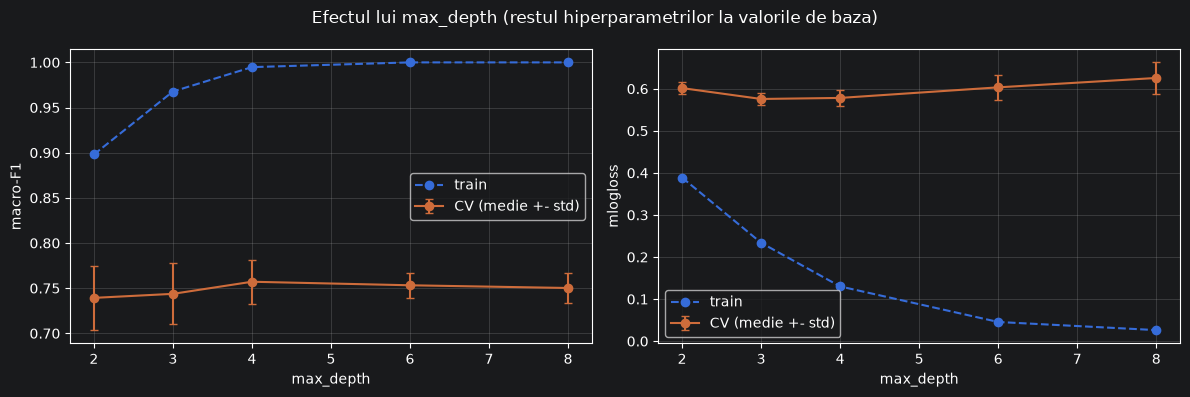

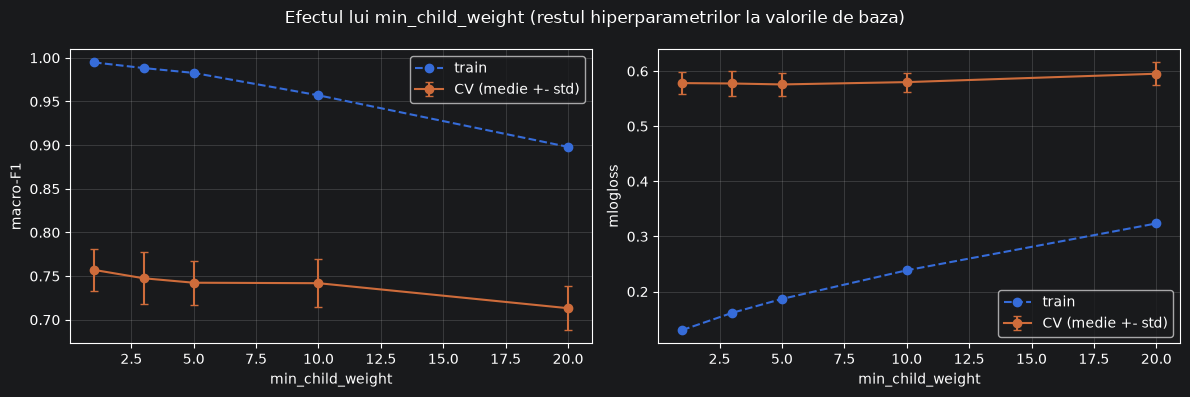

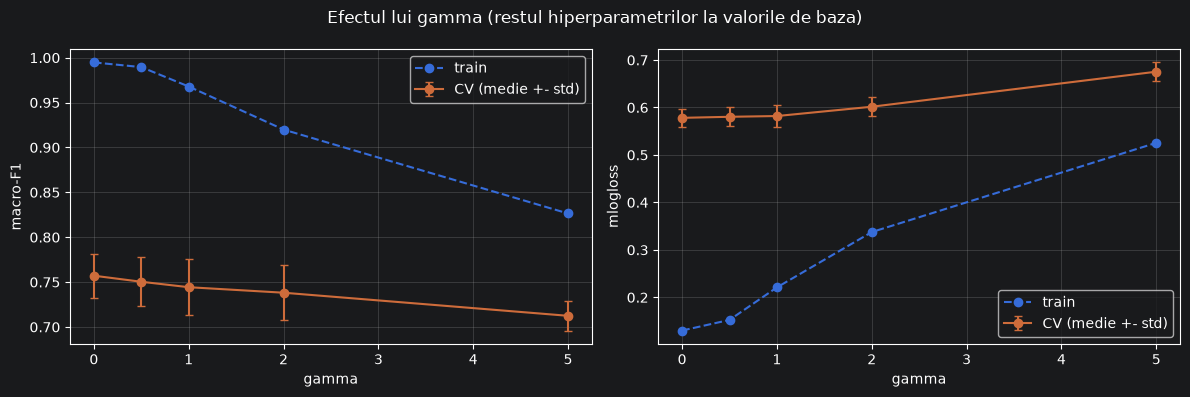

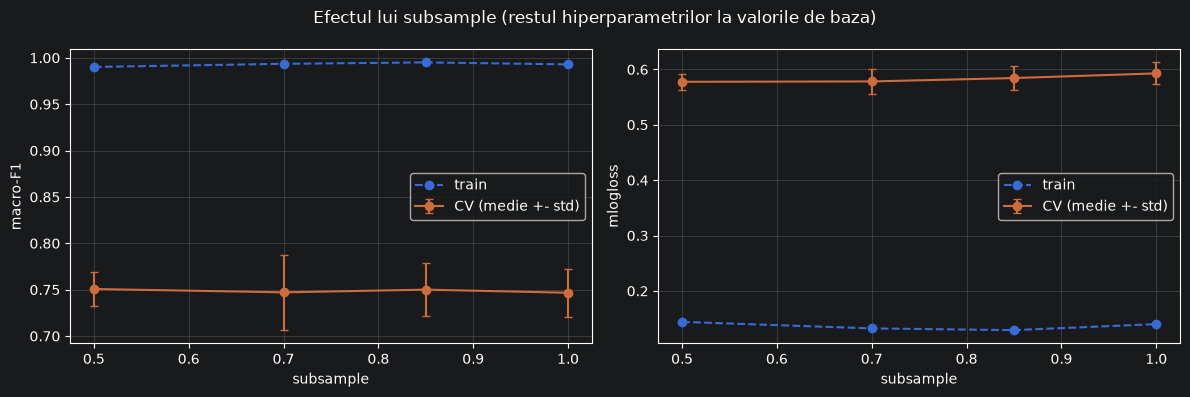

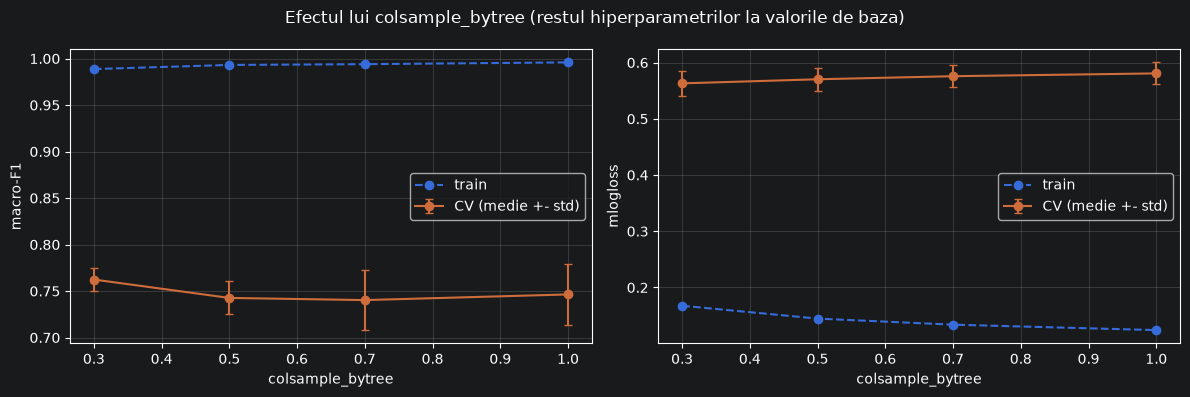

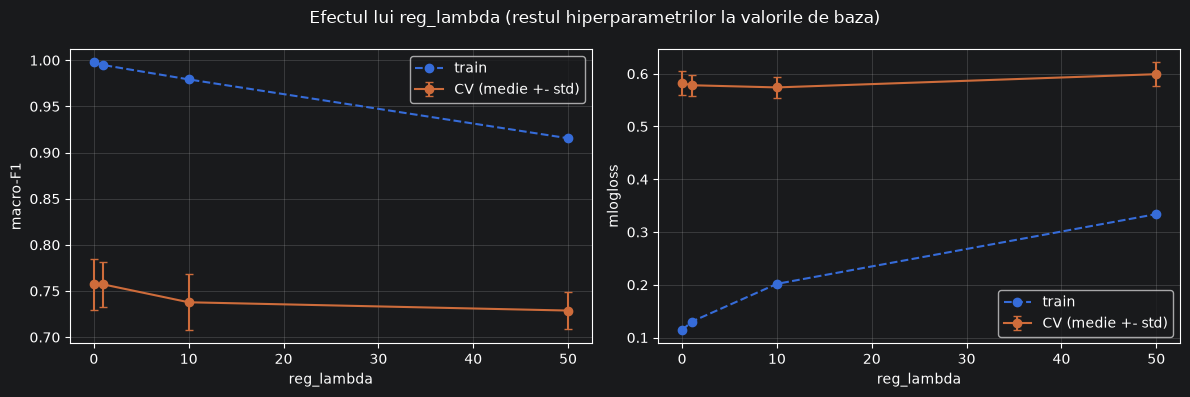

In [12]:
sweeps = {}
for name, values in B.SWEEP_GRID.items():
    sweeps[name] = B.sweep_param(name, values, folds, use_class_weight=USE_CLASS_WEIGHT)
    B.plot_sweep(sweeps[name], SAVE_DIR)

In [13]:
pd.concat(sweeps.values()).set_index(["param","value"]).round(4)

train_f1   cv_f1  cv_f1_std  train_logloss  \
param            value                                               
max_depth        2.00     0.8980  0.7393     0.0357         0.3888   
                 3.00     0.9678  0.7437     0.0339         0.2337   
                 4.00     0.9948  0.7571     0.0244         0.1300   
                 6.00     1.0000  0.7532     0.0141         0.0455   
                 8.00     1.0000  0.7502     0.0163         0.0262   
min_child_weight 1.00     0.9948  0.7571     0.0244         0.1300   
                 3.00     0.9882  0.7475     0.0297         0.1613   
                 5.00     0.9827  0.7424     0.0252         0.1866   
                 10.00    0.9570  0.7419     0.0275         0.2386   
                 20.00    0.8980  0.7132     0.0251         0.3236   
gamma            0.00     0.9948  0.7571     0.0244         0.1300   
                 0.50     0.9895  0.7504     0.0275         0.1524   
                 1.00     0.9679  0.7443     0.0309         0.2210   
                 2.00     0.9199  0.7382     0.0309         0.3375   
                 5.00     0.8264  0.7124     0.0164         0.5255   
subsample        0.50     0.9902  0.7507     0.0187         0.1440   
                 0.70     0.9935  0.7471     0.0407         0.1322   
                 0.85     0.9951  0.7500     0.0283         0.1291   
                 1.00     0.9929  0.7467     0.0256         0.1400   
colsample_bytree 0.30     0.9887  0.7624     0.0127         0.1675   
                 0.50     0.9931  0.7426     0.0177         0.1446   
                 0.70     0.9940  0.7403     0.0323         0.1338   
                 1.00     0.9959  0.7464     0.0330         0.1241   
reg_lambda       0.00     0.9976  0.7571     0.0272         0.1141   
                 1.00     0.9948  0.7571     0.0244         0.1300   
                 10.00    0.9792  0.7378     0.0302         0.2018   
                 50.00    0.9155  0.7288     0.0203         0.3340   

                        cv_logloss  cv_logloss_std  
param            value                              
max_depth        2.00       0.6015          0.0147  
                 3.00       0.5757          0.0144  
                 4.00       0.5782          0.0195  
                 6.00       0.6033          0.0302  
                 8.00       0.6256          0.0370  
min_child_weight 1.00       0.5782          0.0195  
                 3.00       0.5775          0.0220  
                 5.00       0.5757          0.0203  
                 10.00      0.5800          0.0171  
                 20.00      0.5952          0.0206  
gamma            0.00       0.5782          0.0195  
                 0.50       0.5804          0.0196  
                 1.00       0.5820          0.0241  
                 2.00       0.6016          0.0195  
                 5.00       0.6754          0.0196  
subsample        0.50       0.5777          0.0139  
                 0.70       0.5783          0.0230  
                 0.85       0.5844          0.0212  
                 1.00       0.5928          0.0199  
colsample_bytree 0.30       0.5630          0.0218  
                 0.50       0.5703          0.0203  
                 0.70       0.5758          0.0194  
                 1.00       0.5808          0.0196  
reg_lambda       0.00       0.5823          0.0227  
                 1.00       0.5782          0.0195  
                 10.00      0.5741          0.0204  
                 50.00      0.5992          0.0223

**Hiperparametri modificați manual.** Pentru fiecare parametru variem o singură valoare, păstrând restul fixe, și raportăm macro-F1 și logloss pe train și CV (medie ± deviație standard *sample* între folduri). Logloss-ul este calculat fără ponderi de evaluare, pe distribuția naturală a claselor, atât pe train cât și pe validare; ponderile afectează antrenarea, nu definiția metricii raportate. Train mult mai bun decât CV indică varianță/overfitting; scoruri mici atât pe train, cât și pe CV indică bias/underfitting. Nu alegem un parametru doar după maximul punctual: diferențele trebuie comparate cu variația între folduri.

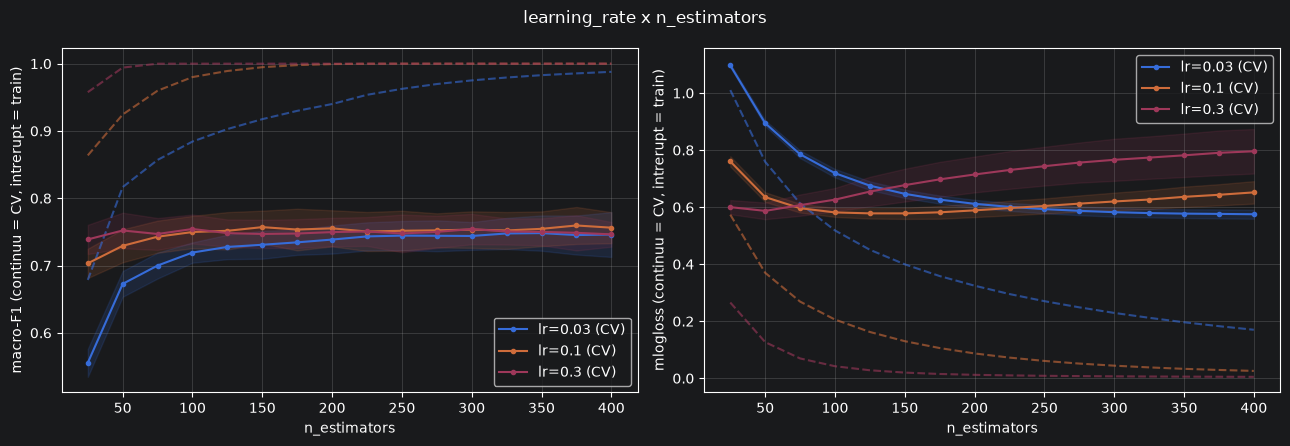

,learning_rate,n_estimators,train_f1,cv_f1,cv_f1_std,cv_logloss
13,0.03,350,0.9829,0.7483,0.0262,0.5773
30,0.10,375,1.0000,0.7596,0.0275,0.6433
35,0.30,100,1.0000,0.7543,0.0215,0.6263


In [14]:
lr_df = B.sweep_lr_nestimators(folds, learning_rates=(0.03, 0.1, 0.3), max_rounds=400, use_class_weight=USE_CLASS_WEIGHT)
B.plot_lr_nestimators(lr_df, SAVE_DIR)
lr_df.loc[lr_df.groupby("learning_rate")["cv_f1"].idxmax(), ["learning_rate","n_estimators","train_f1","cv_f1","cv_f1_std","cv_logloss"]].round(4)

In [15]:
rows = []
for name, df_s in sweeps.items():
    best, within = B.best_by_sweep(df_s)
    r = df_s.loc[df_s["cv_f1"].idxmax()]
    rows.append({"hiperparametru": name, "cea mai buna valoare": best, "CV macro-F1": round(r.cv_f1, 4),
                 "train macro-F1": round(r.train_f1, 4), "valori la <=1 std": within})
pd.DataFrame(rows)

,hiperparametru,cea mai buna valoare,CV macro-F1,train macro-F1,valori la <=1 std
0,max_depth,4.0,0.7571,0.9948,"[2, 3, 4, 6, 8]"
1,min_child_weight,1.0,0.7571,0.9948,"[1, 3, 5, 10]"
2,gamma,0.0,0.7571,0.9948,"[0.0, 0.5, 1.0, 2.0]"
3,subsample,0.5,0.7507,0.9902,"[0.5, 0.7, 0.85, 1.0]"
4,colsample_bytree,0.3,0.7624,0.9887,[0.3]
5,reg_lambda,1.0,0.7571,0.9948,"[0.0, 1.0, 10.0]"


**Interpretarea sweep-urilor.** Toate comparațiile sunt făcute pe CV 5-fold stratificat pe train, cu 150 de runde fixe, fără ponderi și variind câte un singur parametru. Modelul de referință (`max_depth=4`, `min_child_weight=1`, `gamma=0`, `reg_lambda=1`) are macro-F1 pe CV **0,7571 ± 0,0244** și pe train **0,9948**, deci un gap de aproximativ **0,24**: bias mic și varianță mare (overfitting). Logloss-ul este **0,130** pe train și **0,578** pe CV, adică modelul e mult mai sigur pe exemplele pe care le-a văzut decât pe cele noi.

**Observație generală.** Macro-F1 pe CV se mișcă doar între **0,712** (`gamma=5`) și **0,762** (`colsample_bytree=0,3`), iar deviația standard între folduri este **0,013–0,041**. Majoritatea diferențelor dintre valori (de ordinul 0,005–0,015) sunt deci mai mici decât variația dintre folduri și nu pot fi interpretate ca un câștigător clar. Singurele scăderi care depășesc clar deviația standard apar la valori extreme de regularizare, pe care le discutăm mai jos. Logloss-ul variază mai neted și arată mai bine efectul fiecărui parametru, motiv pentru care îl folosim ca al doilea criteriu.

**Parametri care reglează complexitatea arborilor**

* **`max_depth`** (2, 3, 4, 6, 8). Train-F1 crește de la 0,898 la 1,000 (de la adâncimea 6 modelul memorează complet train-ul), iar CV-F1 rămâne în 0,739–0,757, în limita deviației standard. Logloss-ul CV are formă de U: 0,602 la adâncimea 2, minim 0,576 la 3 și 0,578 la 4, apoi 0,603 la 6 și 0,626 la 8. Adâncimea 2 este **underfitting** ușor (train-F1 doar 0,898 și logloss mare și pe train, 0,389). La 6 și 8 este **overfitting prin supra-încredere**: logloss-ul pe train scade la 0,046 și 0,026, dar pe CV crește, deși macro-F1 nu scade, fiindcă argmax-ul e mai puțin sensibil la probabilități prea mari. Zona rezonabilă este adâncimea **3–6**.
* **`min_child_weight`** (1, 3, 5, 10, 20). Valori mai mari interzic frunzele cu puține exemple, deci train-F1 scade de la 0,995 la 0,898. Până la 10, CV-F1 (0,742–0,757) și logloss-ul CV (0,576–0,580) rămân practic neschimbate. La **20** apare **underfitting**: CV-F1 coboară la 0,713 și logloss-ul crește la 0,595. Interval util: **1–10**.
* **`gamma`** (0, 0,5, 1, 2, 5). Un split se face doar dacă reduce pierderea cu cel puțin `gamma`. Până la 1, efectul este mic (train 0,995 → 0,968, logloss CV 0,578 → 0,582). La 2, train-F1 scade la 0,920 și logloss-ul crește la 0,602. La **5** este **underfitting clar**: train-F1 0,826, CV-F1 0,712 și logloss CV 0,675. Interval util: **0–2**.
* **`reg_lambda`** (0, 1, 10, 50). Penalizarea L2 pe valorile din frunze. Train-F1 scade de la 0,998 la 0,916. Logloss-ul CV este cel mai bun la **10** (0,574, față de 0,582 la 0 și 0,578 la 1), iar la **50** apare underfitting (CV-F1 0,729, logloss 0,599). Interval util: **0–10**, eventual până la 20.

**Parametri care introduc aleatorizare**

* **`subsample`** (0,5, 0,7, 0,85, 1,0). Macro-F1 pe CV rămâne în 0,747–0,751 (std 0,019–0,041), deci efectul asupra scorului este neconcludent. Logloss-ul se îmbunătățește monoton cu fracțiuni mai mici: 0,593 la 1,0, 0,584 la 0,85, 0,578 la 0,7 și 0,578 la 0,5. Folosirea unui subset de rânduri pentru fiecare arbore reduce corelația dintre arbori și, ușor, varianța.
* **`colsample_bytree`** (0,3, 0,5, 0,7, 1,0). Cel mai bun macro-F1 pe CV din tot studiul este la 0,3 (**0,7624 ± 0,0127**), dar F1 nu este monoton (0,743 la 0,5; 0,740 la 0,7; 0,746 la 1,0), deci o parte din diferență este zgomot. Logloss-ul CV este însă monoton: 0,581 la 1,0, 0,576 la 0,7, 0,570 la 0,5 și **0,563 la 0,3**. Cu 299 de coloane (multe one-hot rare), folosirea unui subset mic de coloane la fiecare arbore reduce dependența de câteva variabile dominante (`TotalSF`, `QualxLivArea`). Interval util: **0,3–1,0**.

**`learning_rate` × `n_estimators`.** Cei doi parametri sunt cuplați (pașii mici cer mai multe runde), de aceea sunt studiați împreună: pentru fiecare `learning_rate` s-a antrenat o dată cu 400 de runde și s-a evaluat după fiecare 25 de runde.

* Macro-F1 pe CV converge pentru toate cele trei valori în banda **0,74–0,76**, iar benzile ± std se suprapun complet. Cel mai bun scor pe CV este 0,7596 (`lr=0,1`, 375 de runde), față de 0,7543 (`lr=0,3`, 100 de runde) și 0,7483 (`lr=0,03`, 350 de runde); diferențele sunt mult sub deviația standard (0,022–0,028).
* Logloss-ul arată însă comportamente diferite. Cu **`lr=0,3`** minimul CV este atins foarte devreme (aproximativ 0,59 în jur de 50 de runde), apoi logloss-ul crește constant, la aproximativ 0,80 la 400 de runde, în timp ce pe train scade spre 0: supra-ajustare rapidă. Cu **`lr=0,1`** minimul este în jur de 0,58, între 100 și 150 de runde, apoi crește lent, la aproximativ 0,65 la 400. Cu **`lr=0,03`** curba scade lent și se aplatizează la aproximativ 0,575 la 350–400 de runde, fără semne de supra-ajustare, iar gap-ul train–CV rămâne cel mai mic.
* Pentru `lr=0,1`, macro-F1 maxim (375 de runde) coincide cu un logloss CV de 0,643, mai slab decât cel de la 100–150 de runde (aproximativ 0,58). Scorul F1 continuă să arate bine și după ce probabilitățile au devenit supra-încrezătoare, deci nu detectează singur supra-ajustarea.
* Concluzie: un `learning_rate` mic cu multe runde este mai stabil, iar unul mare cu **early stopping** este mai rapid, dar cu risc de supra-ajustare dacă numărul de runde nu este limitat.

**Ce arată împreună.** Modelul de referință are bias mic și varianță mare. Pârghiile de regularizare (`min_child_weight`↑, `gamma`↑, `reg_lambda`↑, `max_depth`↓, `subsample`↓, `colsample_bytree`↓) coboară scorul pe train și, în zona moderată, îmbunătățesc logloss-ul CV cu aproximativ 0,005–0,015, fără o schimbare semnificativă a macro-F1. Peste un prag (`gamma=5`, `min_child_weight=20`, `reg_lambda=50`, `max_depth=2`) trecem în **underfitting**: scad atât train-ul, cât și CV-ul. Căutarea din Partea C trebuie deci să rămână în zonele moderate de mai sus și să compare configurațiile după media ± deviația standard pe folduri, nu după un maxim punctual. Sweep-urile sunt univariate și nu surprind interacțiunile dintre parametri; acestea rămân în sarcina optimizării cu Optuna.

## Spațiul de căutare propus pentru Partea C (Optuna)

Spațiul de căutare este definit în `B.SEARCH_SPACE`. Optuna va optimiza macro-F1 mediu pe `StratifiedKFold(5, shuffle=True, random_state=42)`, exclusiv pe train. `sample_weight_balanced` rămâne hiperparametru categoric: CV indică un posibil câștig pentru balanced, dar variația între folduri și compromisul cu accuracy trebuie evaluate de Optuna. Se raportează media și deviația standard pe folduri, nu doar cel mai bun scor punctual.

## Rerularea pe modelul final (după Partea C)

```python
model_final = B.fit_xgb(
    X_train, y_train, preprocessor,
    params=best_params_from_optuna,
    use_class_weight=best_params_from_optuna_uses_weights,
)
out = B.full_report(
    model_final, X_train, y_train, X_test, y_test,
    save_dir="figures_B_final",
)
```

În această etapă se regenerează arborii, feature importance, metricile și pragurile pentru modelul final. Nu reutiliza pragurile estimate pentru modelul baseline.